# Transcorrelated Hamiltonians and non-Hermitian VarQITE

The transcorrelated (TC) method incorporates electron correlation into the Hamiltonian itself, by a similarity transformation with a Jastrow factor $e^{\hat{\tau}}$,

$$\bar{H} = e^{-\hat{\tau}} H e^{\hat{\tau}}.$$

$\bar{H}$ has the same spectrum as $H$, but its right eigenvectors $e^{-\hat{\tau}}|\Psi\rangle$ are much more compact. Hence, smaller basis sets and shallower circuits reach a given accuracy [1-4]. The price is that $\bar{H}$ is **not Hermitian** and contains **three-body terms**.

In this tutorial, you will learn how to

1. read TC integrals from FCIDUMP and TCDUMP files (e.g. written by the TCHInt library), including approximations without three-body terms such as xTC,
2. detect non-Hermitian Hamiltonians and find their ground state with variational quantum imaginary time evolution (VarQITE),
3. simulate larger systems exactly in the sector of fixed particle numbers,
4. build the transcorrelated Hubbard model,
5. compute biorthogonal energies from left and right eigenvectors, and measure them on quantum hardware,
6. reduce the number of circuits per VarQITE time step, and
7. run VarQITE with shot noise and on (simulated) backends, including error mitigation.

## 1. Transcorrelated integrals

A TC Hamiltonian in second quantization reads

$$\bar{H} = \sum_{pq,\sigma} h_{pq} a^\dagger_{p\sigma} a_{q\sigma} + \frac{1}{2}\sum_{pqrs,\sigma\tau} (pq|rs)\, a^\dagger_{p\sigma} a^\dagger_{r\tau} a_{s\tau} a_{q\sigma} + \frac{1}{2}\sum_{pqrstu,\sigma\tau\lambda} L_{pqr,stu}\, a^\dagger_{p\sigma} a^\dagger_{q\tau} a^\dagger_{r\lambda} a_{u\lambda} a_{t\tau} a_{s\sigma}.$$

The two-body integrals $(pq|rs)$ only have the symmetry $(pq|rs) = (rs|pq)$ under the exchange of the two electrons, instead of the 8-fold symmetry of Hermitian Hamiltonians. The one- and two-body integrals are stored in an FCIDUMP file, which `FCIDump.from_file` now reads without symmetrizing them, if the file has the `ST=1` header entry or contains integrals that contradict the 8-fold symmetry. The three-body integrals are stored in a TCDUMP file, whose 48-fold permutational symmetry is detected automatically, such that only the symmetry-unique integrals are kept in memory (and written by `TCDump.to_file`).

In [1]:
from qiskit_nature.second_q.formats import fcidump_to_problem
from qiskit_nature.second_q.formats.fcidump import FCIDump
from qiskit_nature.second_q.formats.tcdump import TCDump

# TC integrals of the Be atom in the STO-6G basis
fcidump = FCIDump.from_file("aux_files/be_sto6g_tc.fcidump")
tcdump = TCDump.from_file("aux_files/be_sto6g_tc.tcdump")

print("Hermitian integrals:", fcidump.is_hermitian)
print(tcdump.three_body)

Hermitian integrals: False
ThreeBodyIntegrals(num_orbitals=5, symmetry='s48', num_stored=141)


`fcidump_to_problem` combines both files into an `ElectronicStructureProblem`, whose `ElectronicEnergy` Hamiltonian holds the three-body integrals in its `three_body` attribute. Approximations which fold the three-body terms into the one- and two-body integrals, such as the xTC method [4], are fully described by the FCIDUMP file: just omit the TCDUMP argument. (If the FCIDUMP header indicates three-body terms with `III=1` but no TCDUMP is given for a system with three or more electrons, a warning is logged.)

The mapped qubit operator of a non-Hermitian Hamiltonian has complex Pauli coefficients, which is how non-Hermiticity is detected:

In [2]:
from qiskit_nature.second_q.algorithms import is_hermitian_qubit_operator
from qiskit_nature.second_q.mappers import JordanWignerMapper

be_problem = fcidump_to_problem(fcidump, tcdump)
mapper = JordanWignerMapper()
be_qubit_op = mapper.map(be_problem.hamiltonian.second_q_op())

print("number of qubits:", be_qubit_op.num_qubits)
print("number of Pauli terms:", len(be_qubit_op))
print("Hermitian:", is_hermitian_qubit_operator(be_qubit_op))

number of qubits: 10
number of Pauli terms: 960
Hermitian: False


## 2. Solving non-Hermitian Hamiltonians with VarQITE

The VQE minimizes $\langle\psi|H|\psi\rangle$, which is not bounded by the ground-state energy for non-Hermitian $H$, and estimator primitives reject non-Hermitian observables. Imaginary time evolution, $|\psi(\tau)\rangle \propto e^{-\tau \bar{H}}|\psi(0)\rangle$, on the other hand, converges to the right eigenvector whose eigenvalue has the lowest real part, also for non-Hermitian Hamiltonians. Its variational form (VarQITE), based on the variational principle of McLachlan, solves the linear equations

$$\sum_j A_{ij}\dot{\theta}_j = C_i, \quad A_{ij} = \mathrm{Re}\left[\langle\partial_i\psi|\partial_j\psi\rangle - \langle\partial_i\psi|\psi\rangle\langle\psi|\partial_j\psi\rangle\right], \quad C_i = -\mathrm{Re}\left[\langle\partial_i\psi|\bar{H}|\psi\rangle - \langle\partial_i\psi|\psi\rangle\langle\psi|\bar{H}|\psi\rangle\right]$$

at every time step. Writing $\bar{H} = \hat{A} + i\hat{B}$ with Hermitian $\hat{A}$ and $\hat{B}$, the gradient $C$ consists of the usual energy gradient of $\hat{A}$ and an "imaginary" gradient of $\hat{B}$, which are both measured with estimator primitives.

The `GroundStateEigensolver` detects non-Hermitian Hamiltonians and replaces an estimator-based minimum eigensolver like the VQE by a `VarQITEMinimumEigensolver` with the same ansatz, initial point and estimator (with a warning). Here, we use the TC Hamiltonian of LiH in the space of four natural orbitals (8 qubits):

In [3]:
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE, NumPyMinimumEigensolver
from qiskit_algorithms.optimizers import SLSQP

from qiskit_nature.second_q.algorithms import GroundStateEigensolver
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock

problem = fcidump_to_problem(FCIDump.from_file("aux_files/lih_4nos_tc.fcidump"))
norb, nelec = problem.num_spatial_orbitals, problem.num_particles

exact_solver = NumPyMinimumEigensolver(filter_criterion=problem.get_default_filter_criterion())
exact = GroundStateEigensolver(mapper, exact_solver).solve(problem).total_energies[0].real

ansatz = UCCSD(norb, nelec, mapper, initial_state=HartreeFock(norb, nelec, mapper))
vqe = VQE(StatevectorEstimator(), ansatz, SLSQP())
result = GroundStateEigensolver(mapper, vqe).solve(problem)

print(f"TC-FCI energy:    {exact:.8f} Ha")
print(f"VarQITE energy:   {result.total_energies[0]:.8f} Ha")

/var/folders/4k/w9s_bs8x5xq7rw0lkwsz8sm80000gn/T/ipykernel_93574/3607294918.py:16: UserWarning: The qubit operator is not Hermitian (its Pauli representation has complex coefficients), which is not supported by the VQE. Using a VarQITEMinimumEigensolver with the same ansatz instead, which converges to the right eigenvector whose eigenvalue has the lowest real part. Use the `non_hermitian_solver` argument to configure this solver.
  result = GroundStateEigensolver(mapper, vqe).solve(problem)


TC-FCI energy:    -8.02339590 Ha
VarQITE energy:   -8.02339606 Ha


The `VarQITEMinimumEigensolver` can also be used directly. By default, it integrates the equations of motion with forward Euler steps of $\Delta\tau = 0.05$ until $\|\dot\theta\| < 10^{-6}$. For exact simulations, it uses the `StatevectorImaginaryMcLachlanPrinciple`, which propagates the state and all its parameter derivatives through the circuit at once and is orders of magnitude faster than the evaluation of gradient circuits.

converged: True after 384 time steps


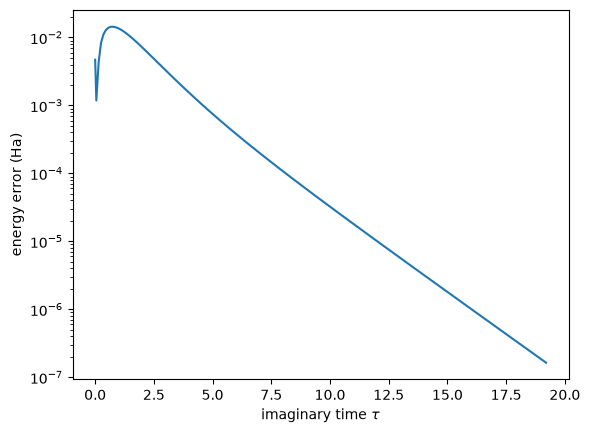

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from qiskit_nature.second_q.algorithms import VarQITEMinimumEigensolver

qubit_op = mapper.map(problem.hamiltonian.second_q_op())
offset = sum(problem.hamiltonian.constants.values())
var_qite = VarQITEMinimumEigensolver(ansatz)
right = var_qite.compute_minimum_eigenvalue(qubit_op)
print("converged:", right.converged, "after", len(right.evolution_result.times) - 1, "time steps")

plt.semilogy(right.times, np.abs(np.real(right.energies) + offset - exact))
plt.xlabel(r"imaginary time $\tau$")
plt.ylabel("energy error (Ha)");

## 3. Larger systems: simulation in the particle-number sector

The cost of simulating the qubit circuit grows with $2^{n_\mathrm{qubits}}$. The `FermionicVarQITESolver` simulates the VarQITE of a `UCC` ansatz exactly in the sector of fixed particle numbers, using the optional [ffsim](https://github.com/qiskit-community/ffsim) library. Its parameters agree with those of the qubit circuit. For the Be atom with its three-body terms, the UCCSD ansatz comes within a few microhartree of the TC-FCI energy of -14.66465 Ha:

In [5]:
import time

from qiskit_nature.second_q.algorithms import FermionicVarQITESolver

be_ansatz = UCCSD(
    be_problem.num_spatial_orbitals,
    be_problem.num_particles,
    mapper,
    initial_state=HartreeFock(be_problem.num_spatial_orbitals, be_problem.num_particles, mapper),
)
start = time.perf_counter()
be_result = FermionicVarQITESolver(be_ansatz).solve(be_problem)
print(f"{be_ansatz.num_parameters} parameters, {time.perf_counter() - start:.1f} s")
print(f"VarQITE energy: {be_result.total_energies[0]:.8f} Ha")

54 parameters, 4.3 s
VarQITE energy: -14.66465180 Ha


## 4. The transcorrelated Hubbard model

The `TranscorrelatedFermiHubbardModel` similarity transforms the Hubbard model of a chain with the Gutzwiller correlator $\hat{g} = J\sum_i n_{i\uparrow}n_{i\downarrow}$ [2],

$$H_{TC} = e^{-\hat{g}} H e^{\hat{g}} = U\sum_i n_{i\uparrow}n_{i\downarrow} - t\sum_{\langle i,j\rangle,\sigma} a^\dagger_{i\sigma}a_{j\sigma}\left[1 + (e^{J}-1)n_{j\bar\sigma} + (e^{-J}-1)n_{i\bar\sigma} - 2(\cosh J - 1)n_{i\bar\sigma}n_{j\bar\sigma}\right],$$

in the site basis or, for periodic boundary conditions, in the momentum basis, where it contains three-body terms. As in Ref. [2], the transcorrelated momentum-space Hamiltonian of a ring of four sites at half filling ($t = 1$, $U = 4$, $J = -0.73$) is solved by one layer of UCCSD orders of magnitude more accurately than the other representations:

In [6]:
from qiskit_nature.second_q.hamiltonians import TranscorrelatedFermiHubbardModel
from qiskit_nature.second_q.problems import LatticeModelProblem

hubbard_ansatz = UCCSD(4, (2, 2), mapper, initial_state=HartreeFock(4, (2, 2), mapper))
exact_hubbard = -2.10274848

for basis in ("real", "momentum"):
    for correlation in (0.0, -0.73):
        model = TranscorrelatedFermiHubbardModel(
            4, hopping=1.0, onsite_interaction=4.0, correlation=correlation, basis=basis
        )
        result = FermionicVarQITESolver(hubbard_ansatz).solve(LatticeModelProblem(model))
        error = abs(result.eigenvalues[0].real - exact_hubbard)
        print(f"{basis:>8s} basis, J = {correlation:+.2f}: energy error {error:.1e}")

    real basis, J = +0.00: energy error 2.0e-01


    real basis, J = -0.73: energy error 2.2e-01
momentum basis, J = +0.00: energy error 3.3e-02


momentum basis, J = -0.73: energy error 9.5e-05


(In the site basis, the Hartree-Fock state of the ansatz occupies the first sites. Ref. [2] starts from the non-interacting ground state instead, which can be prepared with a `SlaterDeterminant` initial state.)

## 5. Left eigenvectors and biorthogonal energies

The expectation value $\langle R|\bar{H}|R\rangle$ of an approximate right eigenvector $|R\rangle = |R_0\rangle + |\delta R\rangle$ is not variational, and its error is of *first* order in $|\delta R\rangle$. With an approximate left eigenvector $|L\rangle = |L_0\rangle + |\delta L\rangle$, the biorthogonal energy

$$E_{LR} = \frac{\langle L|\bar{H}|R\rangle}{\langle L|R\rangle} = E + \frac{\langle\delta L|\bar{H} - E|\delta R\rangle}{\langle L|R\rangle}$$

is accurate to *second* order. The left eigenvectors of $\bar{H}$ are the right eigenvectors of $\bar{H}^\dagger$, so a VarQITE of $\bar{H}^\dagger$ yields $|L\rangle$:

In [7]:
lih_ansatz = UCCSD(norb, nelec, mapper, initial_state=HartreeFock(norb, nelec, mapper))
right = FermionicVarQITESolver(lih_ansatz).solve(problem)
left = FermionicVarQITESolver(lih_ansatz, adjoint=True).solve(problem)
right_point = right.raw_result.optimal_point
left_point = left.raw_result.optimal_point

energy_lr = FermionicVarQITESolver(lih_ansatz).biorthogonal_energy(problem, left_point, right_point)
print(f"error of <R|H|R>:      {right.total_energies[0].real - exact:+.1e} Ha")
print(f"error of <L|H|R>/<L|R>: {energy_lr.real + offset - exact:+.1e} Ha")

error of <R|H|R>:      -1.6e-07 Ha
error of <L|H|R>/<L|R>: -1.7e-12 Ha


The remaining error of $\langle R|\bar{H}|R\rangle$ stems from the convergence threshold of the evolution, and the biorthogonal energy squares it. This requires, however, that the ansatz represents the left eigenvector as well as the right one. For the Gutzwiller-correlated Hubbard model, the left eigenvector $e^{+\hat{g}}|\Psi\rangle$ is *less* compact than $|\Psi\rangle$, and we found no improvement for the four- and six-site rings.

**Measuring $E_{LR}$ on a quantum computer.** Both states are prepared by the same ansatz with different parameters. The `transition_circuit` prepares $\frac{1}{\sqrt{2}}(|0\rangle|L\rangle + |1\rangle|R\rangle)$ with one ancilla qubit: every parameterized rotation $R_Z(\phi(\theta_L))$ is followed by an ancilla-controlled $R_Z(\phi(\theta_R) - \phi(\theta_L))$, so only one controlled rotation is added per rotation angle (none for equal parameters). Then

$$\langle L|P|R\rangle = \langle X\otimes P\rangle + i\langle Y\otimes P\rangle$$

for every Pauli operator $P$, including $P = I$ for $\langle L|R\rangle$. `biorthogonal_expectation_value` measures the four Hermitian observables $X\otimes\hat{A} - Y\otimes\hat{B}$, $Y\otimes\hat{A} + X\otimes\hat{B}$, $X\otimes I$ and $Y\otimes I$, which share the measurement bases of $\bar{H}$ with the ancilla in the $X$ or $Y$ basis: twice the measurements of one energy evaluation, needed only once after both evolutions.

In [8]:
from qiskit import transpile

from qiskit_nature.second_q.algorithms import biorthogonal_expectation_value, transition_circuit

circuit = transition_circuit(lih_ansatz, left_point, right_point)
# the same decomposition of the ansatz, without the ancilla
decomposed = transpile(lih_ansatz, basis_gates=["rz", "sx", "x", "cx"], optimization_level=0)
print("ansatz:            ", dict(decomposed.count_ops()))
print("transition circuit:", dict(circuit.count_ops()))

measured = biorthogonal_expectation_value(
    qubit_op, lih_ansatz, left_point, right_point, StatevectorEstimator()
)
print(f"measured E_LR: {measured.real + offset:.8f} Ha")

ansatz:             {'rz': 1332, 'cx': 768, 'sx': 624, 'x': 2}
transition circuit: {'rz': 1332, 'cx': 768, 'sx': 624, 'crz': 28, 'x': 2, 'h': 1}


measured E_LR: -8.02339590 Ha


## 6. Fewer circuits per time step

At every time step, VarQITE needs the gradient $C$ ($n$ circuits for $n$ parameters, $2n+1$ for non-Hermitian Hamiltonians) and the metric $A$ ($n(n+1)/2$ circuits). The `ApproximateMetricPrinciple` reduces the latter: it evaluates only the block-diagonal or diagonal part of the metric, reuses it for several time steps, or updates it with the rank-one qBroyden rule [5]

$$A_{k+1} = (1-\varepsilon_k)A_k + \varepsilon_k C_k C_k^T, \quad \varepsilon_k = \varepsilon_0/(k+1),$$

starting from an evaluated metric or from the identity, without any further circuits. Since the stationary points of $A\dot\theta = C$ are given by $C = 0$ for any positive-definite $A$, all variants converge to the same state; they differ in the path and in the number of steps:

In [9]:
from qiskit_nature.second_q.algorithms import (
    ApproximateMetricPrinciple,
    StatevectorImaginaryMcLachlanPrinciple,
)

variants = {
    "full metric at every step": dict(metric="full", update=None, recompute_interval=1),
    "full metric every 10 steps": dict(metric="full", update=None, recompute_interval=10),
    "diagonal metric at every step": dict(metric="diagonal", update=None, recompute_interval=1),
    "qBroyden, initial full metric": dict(metric="full", update="qbroyden"),
    "qBroyden, initial identity": dict(metric="identity", update="qbroyden"),
}
for label, options in variants.items():
    principle = ApproximateMetricPrinciple(StatevectorImaginaryMcLachlanPrinciple(), **options)
    result = VarQITEMinimumEigensolver(
        lih_ansatz, variational_principle=principle
    ).compute_minimum_eigenvalue(qubit_op)
    print(
        f"{label:30s}: error {result.eigenvalue.real + offset - exact:+.1e} Ha, "
        f"{len(result.evolution_result.times) - 1:3d} steps, "
        f"{principle.num_metric_entries:5d} metric circuits"
    )

full metric at every step     : error -1.6e-07 Ha, 384 steps, 46080 metric circuits


full metric every 10 steps    : error -1.7e-07 Ha, 384 steps,  4680 metric circuits


diagonal metric at every step : error -1.9e-07 Ha, 393 steps,  5895 metric circuits


qBroyden, initial full metric : error -5.7e-08 Ha, 160 steps,   120 metric circuits


qBroyden, initial identity    : error -1.1e-08 Ha,  52 steps,     0 metric circuits


For ill-conditioned metrics, such as those of hardware-efficient ansätze, a reused metric needs a stronger regularization (e.g. `regularization=1e-3`).

## 7. Shot noise, backends and error mitigation

With an estimator with shot noise, the `VarQITEMinimumEigensolver` measures the gradient and metric circuits with the primitives and, by default, solves the linear equations with a singular-value cutoff of $10^{-2}$, which prevents the amplification of shot noise. Estimators of simulators and quantum hardware require circuits compiled for their backend, which the `transpiler` argument provides. (It must not fix the initial layout, since the gradient circuits contain an ancilla qubit.) Here, we run 20 time steps of the TC Hamiltonian of H$_2$ (STO-6G, two-qubit parity mapping) with a precision of $10^{-3}$ of every expectation value:

In [10]:
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_nature.second_q.mappers import ParityMapper

h2_problem = fcidump_to_problem(FCIDump.from_file("aux_files/h2_sto6g_tc.fcidump"))
parity_mapper = ParityMapper(num_particles=h2_problem.num_particles)
h2_op = parity_mapper.map(h2_problem.hamiltonian.second_q_op())
h2_ansatz = UCCSD(
    2,
    h2_problem.num_particles,
    parity_mapper,
    initial_state=HartreeFock(2, h2_problem.num_particles, parity_mapper),
)

pass_manager = generate_preset_pass_manager(
    optimization_level=1, basis_gates=["rz", "sx", "x", "cx"]
)
noisy_var_qite = VarQITEMinimumEigensolver(
    h2_ansatz,
    estimator=StatevectorEstimator(default_precision=1e-3, seed=7),
    transpiler=pass_manager,
    time=1.0,
)
noisy_result = noisy_var_qite.compute_minimum_eigenvalue(h2_op)
exact_result = VarQITEMinimumEigensolver(h2_ansatz, time=1.0).compute_minimum_eigenvalue(h2_op)
print(f"energy at tau = 1 with shot noise: {noisy_result.eigenvalue.real:.5f} Ha")
print(f"energy at tau = 1 without noise:   {exact_result.eigenvalue.real:.5f} Ha")

energy at tau = 1 with shot noise: -1.93350 Ha
energy at tau = 1 without noise:   -1.93351 Ha


On quantum hardware, pass a Qiskit IBM Runtime `EstimatorV2` and a pass manager for its backend, and enable readout error mitigation (TREX), which removes the large bias that readout errors otherwise cause in the measured gradients and metric:

```python
from qiskit_ibm_runtime import EstimatorV2

estimator = EstimatorV2(mode=backend, options={"resilience_level": 1, "default_precision": 1e-2})
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=backend)
solver = VarQITEMinimumEigensolver(ansatz, estimator=estimator, transpiler=pass_manager, time=5.0)
```

The converged parameters are rather robust to depolarizing noise, which damps $A$ and $C$ but does not shift the stationary point $C = 0$; the energy measured at the converged parameters is more strongly biased. Reference-state error mitigation (REM) [6] corrects it with the noisy and exact energies of a classically simulable reference state, $E_\mathrm{REM} = E_\mathrm{noisy}(\theta) - [E_\mathrm{noisy}(\theta_\mathrm{ref}) - E_\mathrm{exact}(\theta_\mathrm{ref})]$. Since the noise bias depends on the character of the state, a multireference state of similar character (MREM) [7] corrects it more reliably than the Hartree-Fock state.

The same idea applies to the gradient $C$ measured at every time step, whose noise bias shifts the state to which VarQITE converges (the metric only affects the path). The `ReferenceStateMitigatedPrinciple` measures this bias once at a reference state with classically known exact values and subtracts it at every step. This requires a reference that is a *stationary point* of the exact evolution, where the exact gradient vanishes, e.g. the Hartree-Fock state with hardware-efficient layers on top of it: for a non-stationary reference (such as a UCC ansatz at $\theta = 0$) the correction would itself move the converged state, so the principle checks the reference gradient and disables the correction with a warning. For UCC ansätze, apply the reference-state correction to the final energy instead.

```python
from qiskit_nature.second_q.algorithms import ReferenceStateMitigatedPrinciple

principle = ReferenceStateMitigatedPrinciple(
    ImaginaryMcLachlanPrinciple(LinCombQGT(estimator, transpiler=pass_manager),
                                LinCombEstimatorGradient(estimator, transpiler=pass_manager)),
    num_reference_evaluations=4,
)
solver = VarQITEMinimumEigensolver(ansatz, estimator=estimator, transpiler=pass_manager,
                                   variational_principle=principle)
```

The metric does not affect the converged state, but it determines the trajectory. The `OverlapMetricPrinciple` measures it from the overlaps $|\langle\psi(\theta)|\psi(\theta+s)\rangle|^2$ of compute-uncompute circuits with a sampler and divides them by the overlap of the unshifted circuit, whose exact value is one. This built-in reference reduces the damping by gate noise and readout errors at every step (for shallow circuits; the compute-uncompute circuits are twice as deep as the ansatz), which is valuable when the trajectory itself matters, e.g. for imaginary-time properties:

```python
from qiskit_nature.second_q.algorithms import OverlapMetricPrinciple

principle = OverlapMetricPrinciple(principle, sampler, shots=10000, transpiler=pass_manager)
```

## References

[1] S. McArdle and D. P. Tew, Improving the accuracy of quantum computational chemistry using the transcorrelated method, [arXiv:2006.11181](https://arxiv.org/abs/2006.11181) (2020).

[2] I. O. Sokolov, W. Dobrautz, H. Luo, A. Alavi and I. Tavernelli, Orders of magnitude increased accuracy for quantum many-body problems on quantum computers via an exact transcorrelated method, [Phys. Rev. Research 5, 023174 (2023)](https://doi.org/10.1103/PhysRevResearch.5.023174).

[3] W. Dobrautz, I. O. Sokolov, K. Liao, P. López Ríos, M. Rahm, A. Alavi and I. Tavernelli, Toward real chemical accuracy on current quantum hardware through the transcorrelated method, [J. Chem. Theory Comput. 20, 4146 (2024)](https://doi.org/10.1021/acs.jctc.4c00070).

[4] E. M. C. Christlmaier, T. Schraivogel, P. López Ríos, A. Alavi and D. Kats, xTC: An efficient treatment of three-body interactions in transcorrelated methods, [arXiv:2304.07006](https://arxiv.org/abs/2304.07006) (2023).

[5] D. Fitzek, R. S. Jonsson, W. Dobrautz and C. Schäfer, Optimizing variational quantum algorithms with qBang: Efficiently interweaving metric and momentum to navigate flat energy landscapes, [Quantum 8, 1313 (2024)](https://doi.org/10.22331/q-2024-04-09-1313).

[6] P. Lolur, M. Skogh, W. Dobrautz, C. Warren, J. Biznárová, A. Osman, G. Tancredi, G. Wendin, J. Bylander and M. Rahm, Reference-state error mitigation: A strategy for high accuracy quantum computation of chemistry, [J. Chem. Theory Comput. 19, 783 (2023)](https://doi.org/10.1021/acs.jctc.2c00807).

[7] H. Zou, E. Magnusson, H. Brunander, W. Dobrautz and M. Rahm, Multireference error mitigation for quantum computation of chemistry, Digital Discovery 4, 2521 (2025).

In [11]:
import tutorial_magics

%qiskit_version_table
%qiskit_copyright